# 外資分析:註冊在中國 / 印度 / 土耳其 / 美國的公司,在海外做什麼產業?

**定義**
- 公司所屬國(`home_country`)= 我們之前分類的結果(`proponents_classified.csv`)
- **外資專案** = 專案所在國(Excel 的 `Country`)**不等於**公司所屬國。持股對半的公司(例如 `China|Canada`),專案所在國不在任一個所屬國內才算外資。
- 產業 = Excel 的 `Sectoral Scope` 欄。一個專案可能同時有多個產業,**每個產業各算一次**。

**步驟**
- Step 1 載入資料
- Step 2 第一步:比較「公司所屬國」vs「專案所在國」,標出外資
- Step 3 第二步:拆解 Sectoral Scope
- Step 4 四個國家的外資產業統計與圖
- Step 5 明細表(哪些公司、做在哪個國家)

⚠️ **限制**:沒有查證持股的公司,我是用「專案所在國」推斷所屬國,這類公司**定義上不會是外資**。所以外資數字只來自查證或手動指定過的公司,是**下限**,不是完整數字。

## Step 1. 載入資料

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

HERE = Path.cwd()
# 資料夾結構:code/(程式) data/(csv) Photo/(圖);不管從 code 或上層資料夾開 notebook 都會找到正確位置
ROOT = HERE.parent if HERE.name == "code" else HERE
CODE, DATA, PHOTO = ROOT / "code", ROOT / "data", ROOT / "Photo"
DATA.mkdir(exist_ok=True); PHOTO.mkdir(exist_ok=True)
SRC = Path("/Users/peterchang/Downloads/Verra_active_project.xlsx")

raw = pd.read_excel(SRC, engine="calamine")
classified = pd.read_csv(DATA / "proponents_classified.csv")     # 公司 → 所屬國

# 只留有分類的公司(被跳過的 Multiple Project Proponents 等自然會被排除)
df = raw.merge(classified[["Proponents", "home_country", "confidence", "method"]],
               on="Proponents", how="inner")
print(f"{len(df)} projects with a classified proponent")

1343 projects with a classified proponent


## Step 2. 第一步:標出外資
Excel 的 `Country` 寫法要先統一成和 `home_country` 相同的名稱,才能比較。

In [2]:
COUNTRY_RENAME = {
    "United States of America": "United States",
    "Korea (Republic of)": "South Korea",
    "Tanzania, United Republic of": "Tanzania",
    "Lao People's Democratic Republic": "Laos",
}
df["project_country"] = df["Country"].replace(COUNTRY_RENAME)

# home_country 可能是 "China|Canada"(持股對半),專案國不在任何一個所屬國內才算外資
df["is_foreign"] = df.apply(lambda r: r["project_country"] not in r["home_country"].split("|"), axis=1)

print(f"外資專案 {df['is_foreign'].sum()} / {len(df)} ({df['is_foreign'].mean():.1%})")
print("外資專案的分類依據(推斷的不會是外資):")
print(df[df["is_foreign"]]["method"].value_counts().to_string())

外資專案 235 / 1343 (17.5%)
外資專案的分類依據(推斷的不會是外資):
method
manual                                135
web research (largest shareholder)     94
web search: company location found      6


## Step 3. 第二步:拆解 Sectoral Scope
欄位裡常常是多個產業用逗號串在一起,而且產業名稱本身也有逗號(例如 `Livestock, enteric fermentation, and manure management`),所以不能直接用逗號切,改用「已知的產業名稱」去比對。

In [3]:
SCOPES = [
    "Energy industries (renewable/non-renewable sources)",
    "Energy distribution",
    "Energy demand",
    "Manufacturing industries",
    "Chemical industry",
    "Construction",
    "Transport",
    "Mining/mineral production",
    "Metal production",
    "Fugitive emissions from fuels (solid, oil and gas)",
    "Fugitive emissions from production and consumption of halocarbons and sulphur hexafluoride",
    "Solvent use",
    "Waste handling and disposal",
    "Agriculture Forestry and Other Land Use",
    "Livestock, enteric fermentation, and manure management",
]

def split_scopes(text):
    if pd.isna(text):
        return []
    return [s for s in SCOPES if s in text]

df["scopes"] = df["Sectoral Scope"].map(split_scopes)

# 檢查:有沒有 Sectoral Scope 有值卻一個都沒對到
bad = df[df["Sectoral Scope"].notna() & (df["scopes"].str.len() == 0)]
print("沒拆出任何產業的專案數:", len(bad))

沒拆出任何產業的專案數: 0


## Step 4. 四個國家的外資產業
公司註冊在 **中國、印度、土耳其、美國**,而且專案在海外的專案,依產業統計(一個專案有多個產業時各算一次)。
持股對半的公司會在兩個所屬國各算一次。

In [4]:
TARGETS = ["Mainland China", "India", "Turkey", "United States"]

# 公司所屬國展開(對半公司拆成兩列),只留外資專案、只留目標國家
fx = df[df["is_foreign"]].assign(home=lambda d: d["home_country"].str.split("|")).explode("home")
fx = fx[fx["home"].isin(TARGETS)]

# 每個專案的產業展開
fx_sc = fx.explode("scopes").dropna(subset=["scopes"])

table = (fx_sc.groupby(["home", "scopes"]).size().unstack(0)
              .reindex(columns=TARGETS).fillna(0).astype(int))
table = table.loc[table.sum(axis=1).sort_values(ascending=False).index]
table.loc["(外資專案數,不重複)"] = fx.groupby("home").size().reindex(TARGETS).fillna(0).astype(int)
table

home,Mainland China,India,Turkey,United States
scopes,,,,
Agriculture Forestry and Other Land Use,0,2,0,32
Energy demand,3,5,0,17
Energy industries (renewable/non-renewable sources),12,1,0,8
"Fugitive emissions from fuels (solid, oil and gas)",0,0,0,1
"(外資專案數,不重複)",15,8,0,57


下面是圖:每個國家各一張,橫條 = 產業,長度 = 外資專案數。想改顏色、排序、字體就改這一格。

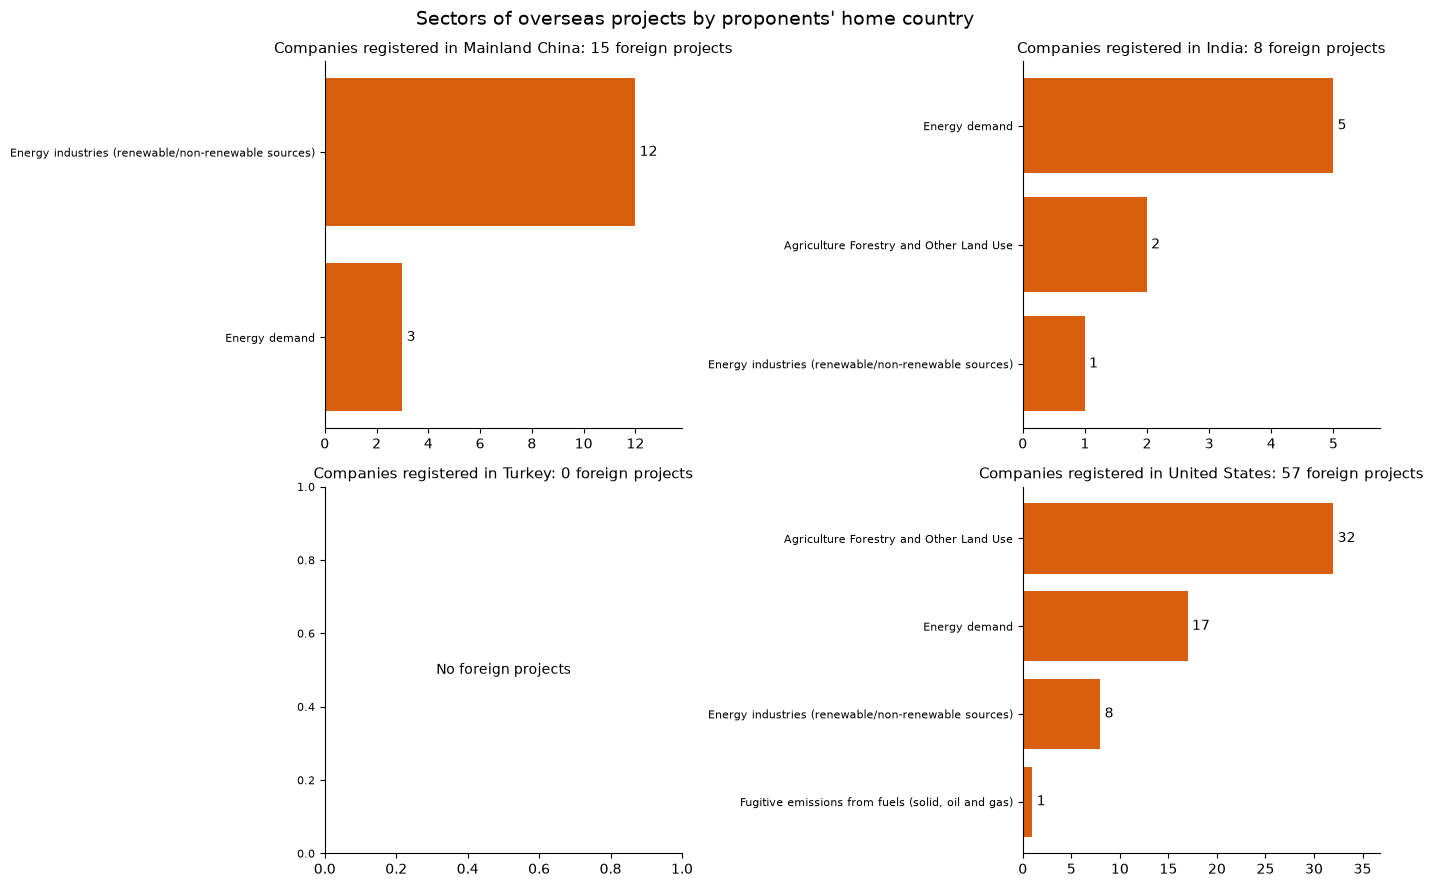

In [5]:
BAR_COLOR = "#d95f0e"

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, country in zip(axes.ravel(), TARGETS):
    s = (fx_sc[fx_sc["home"] == country].groupby("scopes").size().sort_values())
    if s.empty:
        ax.text(0.5, 0.5, "No foreign projects", ha="center", va="center", transform=ax.transAxes)
    else:
        bars = ax.barh(s.index, s.values, color=BAR_COLOR)
        ax.bar_label(bars, padding=3)
        ax.set_xlim(0, s.max() * 1.15)
    ax.set_title(f"Companies registered in {country}: {int(table.loc['(外資專案數,不重複)', country])} foreign projects",
                 fontsize=11)
    ax.tick_params(axis="y", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Sectors of overseas projects by proponents' home country", fontsize=14)
fig.tight_layout()
fig.savefig(PHOTO / "foreign_sectors.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 5. 明細表
哪些公司、做在哪個國家、什麼產業、依據是什麼(`method` / `confidence`),方便你抽查。

In [6]:
detail = (fx[["home", "Proponents", "project_country", "Project Name", "Sectoral Scope", "confidence", "method"]]
          .sort_values(["home", "Proponents"]))
detail.to_csv(DATA / "foreign_projects_detail.csv", index=False, encoding="utf-8-sig")
detail

,home,Proponents,project_country,Project Name,Sectoral Scope,confidence,method
21,India,EKI Energy Services Limited (PP),Bangladesh,Grouped Captive Solar Power Project in Bangladesh,Energy industries (renewable/non-renewable sou...,H,web research (largest shareholder)
525,India,EKI Energy Services Limited (PP),Kenya,Improved Cookstove Distribution in Kenya by EK...,Energy demand,H,web research (largest shareholder)
956,India,EKI Energy Services Limited (PP),Malawi,Improved Cookstove Distribution in Malawi by E...,Energy demand,H,web research (largest shareholder)
1247,India,OYU Green Private Limited (PP),Uganda,OYU - Clean Cooking in Uganda,Energy demand,M,web research (largest shareholder)
1248,India,OYU Green Private Limited (PP),Uganda,OYU - Reforesting Uganda for a better tomorrow,Agriculture Forestry and Other Land Use,M,web research (largest shareholder)
...,...,...,...,...,...,...,...
534,United States,Wildlife Works Carbon LLC,Kenya,The Kasigau Corridor REDD Project – Phase I Ru...,Agriculture Forestry and Other Land Use,H,manual
150,United States,"Wildlife Works Carbon, Inc (PP)",Congo (Democratic Republic of),The Mai Ndombe REDD+ Project,Agriculture Forestry and Other Land Use,H,manual
523,United States,"d.light design, Ltd",Kenya,D.Light's Improved Cooking Project In Kenya,Energy demand,M,manual
1012,United States,"d.light design, Ltd",Nigeria,D.Light's Improved Cooking Project In Nigeria,Energy demand,M,manual


---
## Step 6. 每個國家的外資數量(由多到少)
以**公司所屬國**為單位:該國的公司在海外(專案所在國 ≠ 所屬國)做了多少專案。
- `companies`:至少有一個海外專案的公司數(同一家公司只算一次)
- `projects`:海外專案數
- 持股對半的公司在兩個所屬國各算一次
- 下面圖用哪一個,改 `METRIC` 即可

In [7]:
# Step 6-1. 每個所屬國的外資公司數、外資專案數
fx_all = (df[df["is_foreign"]]
          .assign(home=lambda d: d["home_country"].str.split("|"))
          .explode("home"))

by_country = (fx_all.groupby("home")
              .agg(companies=("Proponents", "nunique"), projects=("Proponents", "size"))
              .sort_values(["companies", "projects"], ascending=False))
by_country.to_csv(DATA / "foreign_by_home_country.csv", encoding="utf-8-sig")
print(f"{len(by_country)} 個國家有外資;外資公司合計 {by_country['companies'].sum()}(對半公司重複計算)")
by_country

27 個國家有外資;外資公司合計 147(對半公司重複計算)


,companies,projects
home,,
United States,30,57
United Kingdom,12,26
Singapore,12,16
France,11,13
Canada,9,19
Switzerland,9,9
Italy,8,11
Mainland China,7,15
India,5,8


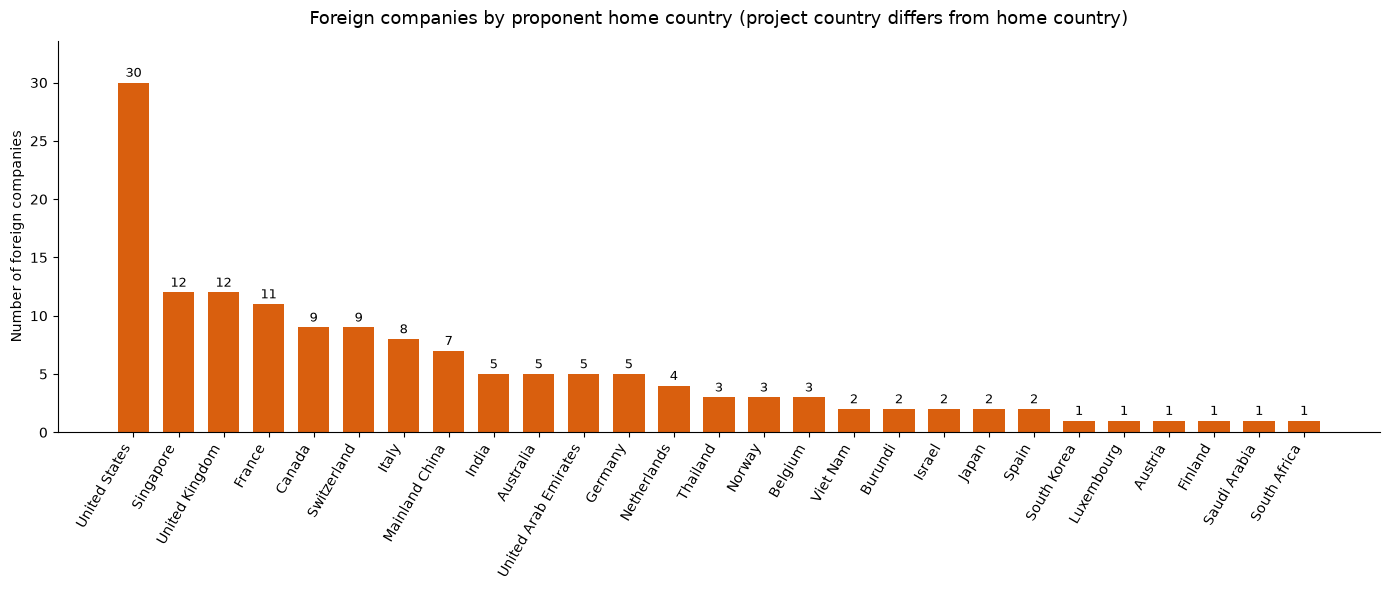

In [8]:
# Step 6-2. 垂直長條圖(想改顏色、標題、"companies" 換成 "projects",改這裡)
METRIC = "companies"            # "companies" 或 "projects"
BAR_COLOR = "#d95f0e"

s = by_country[METRIC].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(s.index, s.values, color=BAR_COLOR, width=0.7)
ax.bar_label(bars, padding=2, fontsize=9)
ax.set_ylabel(f"Number of foreign {METRIC}")
ax.set_title(f"Foreign {METRIC} by proponent home country (project country differs from home country)",
             fontsize=13, pad=12)
ax.set_xticks(range(len(s)))
ax.set_xticklabels(s.index, rotation=60, ha="right")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, s.max() * 1.12)
fig.tight_layout()
fig.savefig(PHOTO / "foreign_by_home_country.png", dpi=200, bbox_inches="tight")
plt.show()

---
## Step 7. 在中國 / 印度 / 土耳其 / 美國做的專案,公司註冊在哪些國家?
- 先挑出**專案所在國**(Excel 的 `Country`)是這四國的專案
- 再看做這些專案的**公司所屬國**(`home_country`)分布
- 包含本國公司(例如在中國的專案,中國公司也會是一條長條)
- 持股對半的公司(例如 `Turkey|Germany`)在兩個所屬國各算一次
- 每個專案只算一次公司所屬國;被跳過的 `Multiple Project Proponents` 專案不在內

In [9]:
# Step 7-1. 在目標國做的專案 → 公司所屬國(對半公司拆成兩列)
TARGETS = ["Mainland China", "India", "Turkey", "United States"]

inb = (df[df["project_country"].isin(TARGETS)]
         .assign(home=lambda d: d["home_country"].str.split("|"))
         .explode("home"))

by_home = (inb.groupby(["project_country", "home"])
              .agg(projects=("Project ID", "nunique"), companies=("Proponents", "nunique"))
              .reset_index()
              .sort_values(["project_country", "projects"], ascending=[True, False]))
by_home.to_csv(DATA / "projects_by_home_country.csv", index=False, encoding="utf-8-sig")

for c in TARGETS:
    t = by_home[by_home["project_country"] == c]
    print(f"{c}: {df[df['project_country']==c]['Project ID'].nunique()} projects, {len(t)} home countries")
by_home

Mainland China: 392 projects, 5 home countries
India: 331 projects, 12 home countries
Turkey: 125 projects, 5 home countries
United States: 39 projects, 3 home countries


,project_country,home,projects,companies
4,India,India,295,192
8,India,Singapore,11,8
1,India,Canada,10,3
7,India,Mainland China,10,3
11,India,United States,4,4
6,India,Luxembourg,3,1
5,India,Japan,2,2
10,India,United Kingdom,2,2
0,India,Australia,1,1
2,India,Finland,1,1


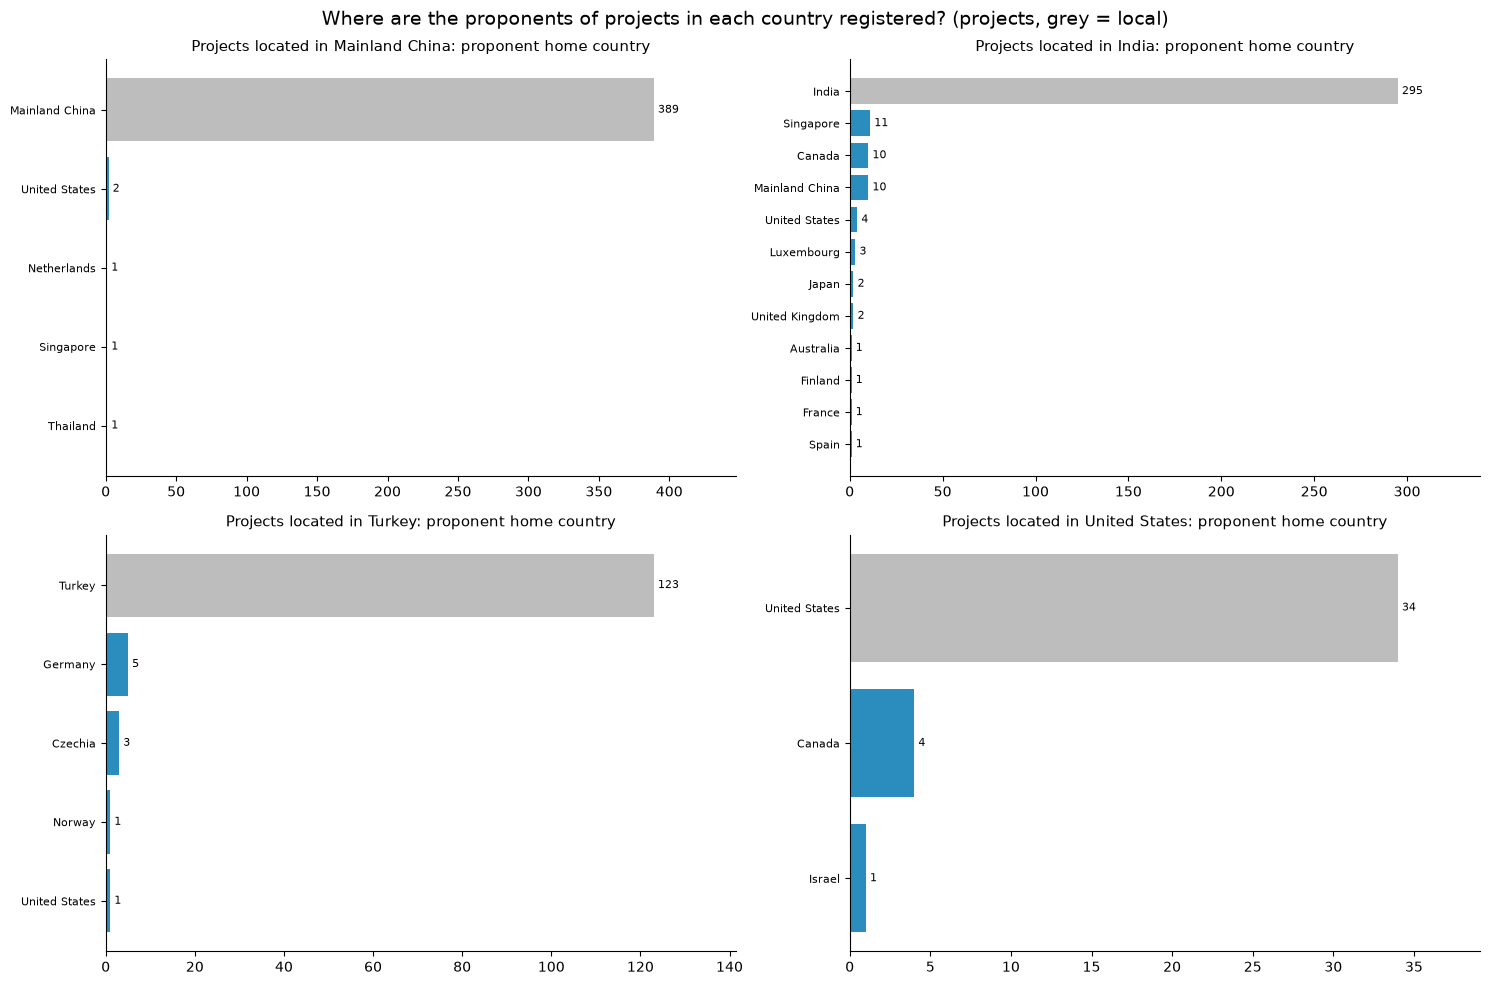

In [10]:
# Step 7-2. 圖:每個子圖 = 一個專案所在國,長條 = 公司所屬國(專案數)
# 想改顏色、只看前幾名、公司數/專案數,改這裡
BAR_COLOR = "#2b8cbe"
LOCAL_COLOR = "#bdbdbd"      # 本國公司用灰色標出
TOP_N = 15
METRIC = "projects"          # "projects" 或 "companies"

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, c in zip(axes.ravel(), TARGETS):
    t = by_home[by_home["project_country"] == c].sort_values(METRIC, ascending=False).head(TOP_N)
    t = t.iloc[::-1]
    colors = [LOCAL_COLOR if h == c else BAR_COLOR for h in t["home"]]
    bars = ax.barh(t["home"], t[METRIC], color=colors)
    ax.bar_label(bars, padding=3, fontsize=8)
    ax.set_xlim(0, t[METRIC].max() * 1.15)
    ax.set_title(f"Projects located in {c}: proponent home country", fontsize=11)
    ax.tick_params(axis="y", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Where are the proponents of projects in each country registered? ({METRIC}, grey = local)", fontsize=14)
fig.tight_layout()
fig.savefig(PHOTO / "projects_by_home_country.png", dpi=200, bbox_inches="tight")
plt.show()

---
## Step 8. 南美洲:在南美洲做專案、但公司註冊在國外
- 專案所在國 ∈ 南美洲 12 國
- **公司註冊在國外** = 公司所屬國 ≠ 專案所在國(例如在巴西的專案,公司在美國;公司在智利、專案在秘魯也算國外)
- 對半持股且其中一方是專案所在國的公司(例如 `Brazil|United Kingdom`)不算國外
- 圖 1:各南美國家的專案,國外公司 vs 本國公司;圖 2:這些國外公司來自哪些國家
- 被跳過的 `Multiple Project Proponents` 專案不在內

In [11]:
# Step 8-1. 南美洲專案,標出國外公司
SOUTH_AMERICA = ["Argentina", "Bolivia (Plurinational State of)", "Bolivia", "Brazil", "Chile", "Colombia", "Ecuador",
                 "Guyana", "Paraguay", "Peru", "Suriname", "Uruguay", "Venezuela (Bolivarian Republic of)", "Venezuela"]

sa = df[df["project_country"].isin(SOUTH_AMERICA)].copy()
sa["is_foreign_co"] = sa.apply(lambda r: r["project_country"] not in r["home_country"].split("|"), axis=1)
print("南美洲專案(有分類的公司):", len(sa), " 國外公司:", sa["is_foreign_co"].sum(),
      f"({sa['is_foreign_co'].mean():.1%})")

sa_sum = (sa.groupby("project_country")
            .agg(projects=("Project ID", "nunique"), foreign_projects=("is_foreign_co", "sum"))
            .assign(local_projects=lambda d: d["projects"] - d["foreign_projects"])
            .sort_values("projects", ascending=False))
sa_sum["foreign_%"] = (sa_sum["foreign_projects"] / sa_sum["projects"] * 100).round(1)
sa_sum

南美洲專案(有分類的公司): 128  國外公司: 25 (19.5%)


,projects,foreign_projects,local_projects,foreign_%
project_country,,,,
Brazil,56,4,52,7.1
Colombia,20,6,14,30.0
Peru,13,5,8,38.5
Chile,12,5,7,41.7
Uruguay,11,0,11,0.0
Argentina,8,2,6,25.0
Paraguay,7,3,4,42.9
Ecuador,1,0,1,0.0


In [12]:
# Step 8-2. 國外公司的明細與來源國(對半公司在兩個所屬國各算一次)
sa_fx = sa[sa["is_foreign_co"]]
sa_detail = (sa_fx[["project_country", "Proponents", "home_country", "Project Name", "Sectoral Scope", "confidence", "method"]]
             .sort_values(["project_country", "home_country", "Proponents"]))
sa_detail.to_csv(DATA / "southamerica_foreign_detail.csv", index=False, encoding="utf-8-sig")

sa_src = (sa_fx.assign(home=lambda d: d["home_country"].str.split("|")).explode("home")
               .groupby("home").agg(projects=("Project ID", "nunique"), companies=("Proponents", "nunique"))
               .sort_values("projects", ascending=False))
sa_src

,projects,companies
home,,
United States,5,5
Canada,4,3
France,4,3
Switzerland,3,3
Germany,2,2
Italy,2,2
United Arab Emirates,2,1
Mainland China,1,1
Spain,1,1


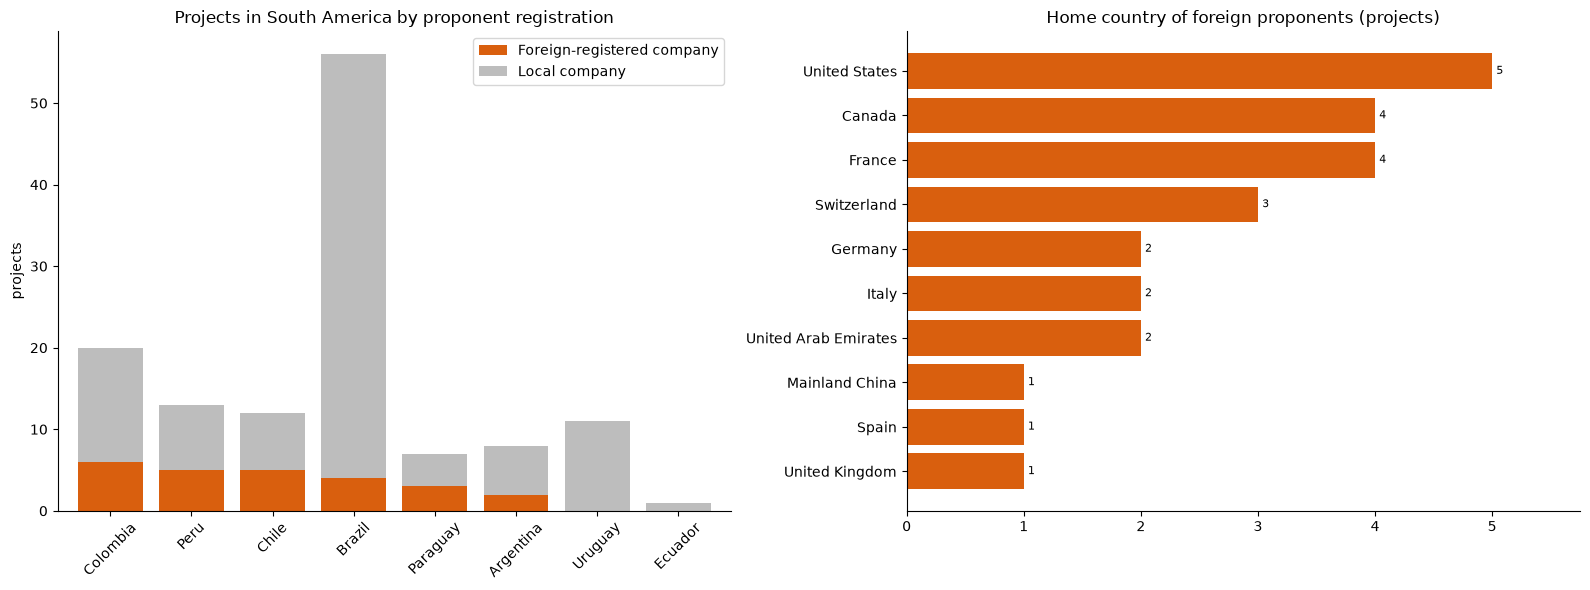

In [13]:
# Step 8-3. 圖(想改顏色、前幾名、projects/companies,改這裡)
FOREIGN_COLOR = "#d95f0e"
LOCAL_COLOR = "#bdbdbd"
TOP_N = 15
METRIC = "projects"            # "projects" 或 "companies"

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 左:各南美國家,本國 vs 國外公司(堆疊)
t = sa_sum[["foreign_projects", "local_projects"]].sort_values("foreign_projects", ascending=False)
t.plot.bar(stacked=True, ax=axes[0], color=[FOREIGN_COLOR, LOCAL_COLOR], rot=45, width=0.8)
axes[0].legend(["Foreign-registered company", "Local company"])
axes[0].set_title("Projects in South America by proponent registration")
axes[0].set_xlabel(""); axes[0].set_ylabel("projects")
axes[0].spines[["top", "right"]].set_visible(False)

# 右:國外公司來自哪個國家
s = sa_src[METRIC].head(TOP_N).iloc[::-1]
bars = axes[1].barh(s.index, s.values, color=FOREIGN_COLOR)
axes[1].bar_label(bars, padding=3, fontsize=8)
axes[1].set_xlim(0, s.max() * 1.15)
axes[1].set_title(f"Home country of foreign proponents ({METRIC})")
axes[1].spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(PHOTO / "southamerica_foreign.png", dpi=200, bbox_inches="tight")
plt.show()

### Step 8-4. 南美洲的國外公司「來自哪些國家」(單獨一張圖)
國外公司的所屬國,由多到少;表格另外列出這些公司做在南美洲哪個國家、公司名單。持股對半的公司在兩個所屬國各算一次。

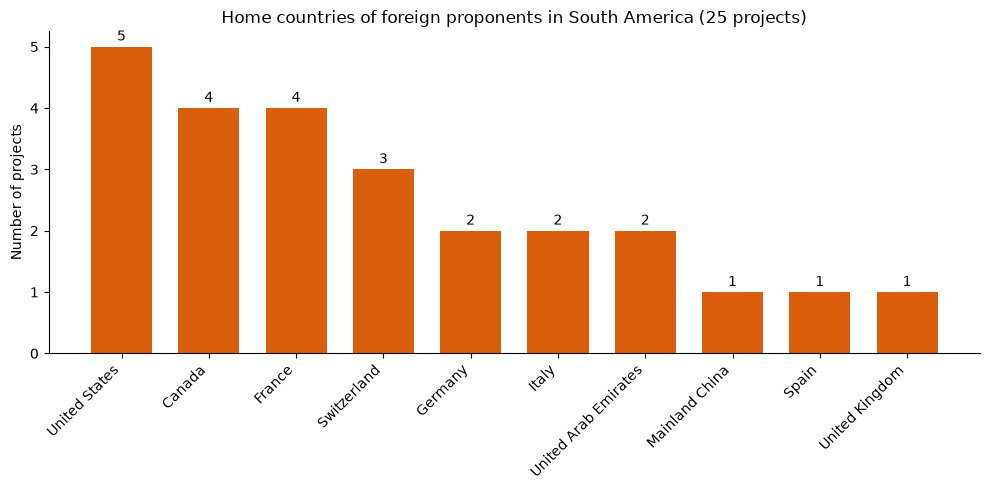

project_country,Argentina,Brazil,Chile,Colombia,Paraguay,Peru,total,companies
home,,,,,,,,
United States,2,0,1,1,0,1,5,5
Canada,0,0,0,3,0,1,4,3
France,0,0,2,0,0,2,4,3
Switzerland,0,0,0,2,1,0,3,3
Germany,0,2,0,0,0,0,2,2
Italy,0,1,1,0,0,0,2,2
United Arab Emirates,0,0,0,0,2,0,2,1
Mainland China,0,0,0,0,0,1,1,1
Spain,0,0,1,0,0,0,1,1


In [14]:
# 來源國 × 南美洲專案所在國(專案數)
sa_x = (sa_fx.assign(home=lambda d: d["home_country"].str.split("|")).explode("home")
             .groupby(["home", "project_country"])["Project ID"].nunique().unstack(fill_value=0))
sa_x["total"] = sa_x.sum(axis=1)
sa_x = sa_x.sort_values("total", ascending=False)
sa_x["companies"] = sa_src["companies"]
sa_x.to_csv(DATA / "southamerica_foreign_by_source.csv", encoding="utf-8-sig")

# 垂直長條圖(想改顏色、標題、METRIC 改這裡)
SRC_COLOR = "#d95f0e"
METRIC = "projects"              # "projects" 或 "companies"
s = sa_src[METRIC].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(s.index, s.values, color=SRC_COLOR, width=0.7)
ax.bar_label(bars, padding=2)
ax.set_ylabel(f"Number of {METRIC}")
ax.set_title(f"Home countries of foreign proponents in South America ({int(sa_fx['Project ID'].nunique())} projects)")
ax.set_xticks(range(len(s))); ax.set_xticklabels(s.index, rotation=45, ha="right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(PHOTO / "southamerica_foreign_sources.png", dpi=200, bbox_inches="tight")
plt.show()
sa_x

### Step 8-5. 這些南美洲國外公司專案做什麼產業
依 Sectoral Scope 統計;一個專案有多個產業時每個產業各算一次(長條總和可能大於專案數)。

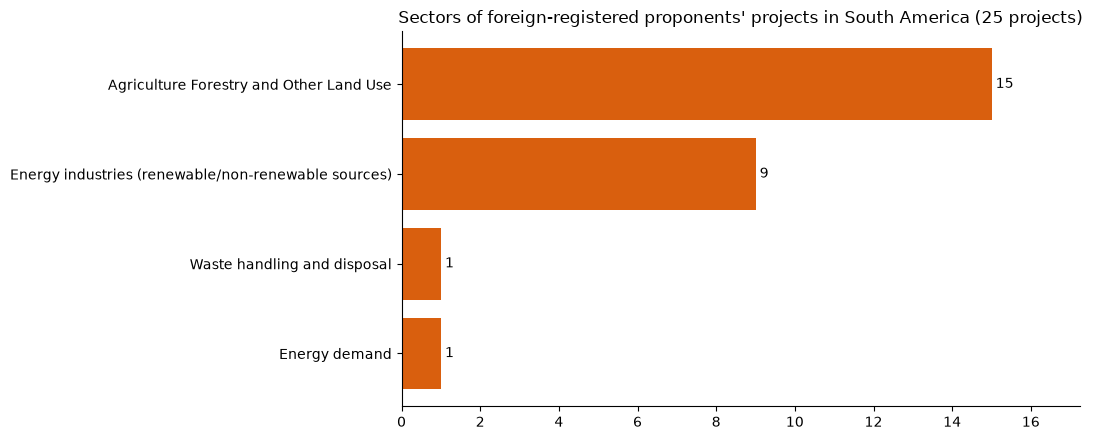

,project_country,Proponents,home_country,Project Name,Sectoral Scope
6,Argentina,"Native, a Public Benefit Corporation (PP)",United States,Patagonia Region Improved Grazing Project,Agriculture Forestry and Other Land Use
47,Brazil,Carbon Credits Consulting S.r.l. (PP),Italy,Fazenda Boa Vista afforestation project,Agriculture Forestry and Other Land Use
61,Brazil,Future Carbon International LLC (PP),Germany,Rio Madeira Grouped REDD+ Project,Agriculture Forestry and Other Land Use
69,Brazil,NaturAll Carbon Limited (PP),United Kingdom,NaturAll Carbon Program – Conservation Agricul...,Agriculture Forestry and Other Land Use
111,Chile,Alto Maipo SpA (PP),United States,AVOIDING PLANNED DEFORESTATION AND DEGRADATION...,Agriculture Forestry and Other Land Use
124,Colombia,ALLCOT A.G. (PP),Switzerland,AFFORESTATION OF DEGRADED GRASSLANDS IN VICHAD...,Agriculture Forestry and Other Land Use
140,Colombia,"Saving Nature, Inc. (PP)",United States,SIVIRÚ-USARAGÁ-PIZARRO-PILIZÁ (SUPP) REDD+ Pro...,Agriculture Forestry and Other Land Use
142,Colombia,Société de gestion de projets ECOTIERRA Inc.,Canada,"Sustainable Agroforestry Cacao Meta, Colombia",Agriculture Forestry and Other Land Use
1032,Paraguay,Green Vantage Enterprises Limited (PP),United Arab Emirates,The Paraguay Forest Conservation Project - Red...,Agriculture Forestry and Other Land Use
1033,Paraguay,Green Vantage Enterprises Limited (PP),United Arab Emirates,The Paraguay Forest Conservation Project – Red...,Agriculture Forestry and Other Land Use


In [15]:
# 產業統計 + 圖(想改顏色、排序改這裡)
SECTOR_COLOR = "#d95f0e"
n_proj = sa_fx["Project ID"].nunique()

sa_sc = sa_fx.explode("scopes").dropna(subset=["scopes"])
sector_tbl = (sa_sc.groupby("scopes")
                   .agg(projects=("Project ID", "nunique"), companies=("Proponents", "nunique"))
                   .sort_values("projects", ascending=False))
sector_tbl.to_csv(DATA / "southamerica_foreign_sectors.csv", encoding="utf-8-sig")

s = sector_tbl["projects"].sort_values()
fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.barh(s.index, s.values, color=SECTOR_COLOR)
ax.bar_label(bars, padding=3)
ax.set_xlim(0, s.max() * 1.15)
ax.set_title(f"Sectors of foreign-registered proponents' projects in South America ({n_proj} projects)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(PHOTO / "southamerica_foreign_sectors.png", dpi=200, bbox_inches="tight")
plt.show()

# 每個專案的產業,方便抽查
sa_fx[["project_country", "Proponents", "home_country", "Project Name", "Sectoral Scope"]].sort_values(["Sectoral Scope", "project_country"])